In [1]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# dług (GD) i saldo (B9), sektor general government (S13), % PKB
filtry = {"unit": "PC_GDP", "sector": "S13", "na_item": ["GD", "B9"]}
raw = eurostat.get_data_df("gov_10dd_edpt1", filter_pars=filtry)

# kolumna z krajem nazywa się zwykle 'geo\TIME_PERIOD' (albo 'geo\\time')
geo_col = [c for c in raw.columns if str(c).startswith("geo")][0]
raw = raw.rename(columns={geo_col: "geo"})

lata = [c for c in raw.columns if str(c).isdigit()]
df = raw.melt(id_vars=["na_item", "geo"], value_vars=lata,
              var_name="rok", value_name="wartosc")
df["rok"] = df["rok"].astype(int)

dlug = df[df.na_item == "GD"].pivot(index="rok", columns="geo", values="wartosc")
saldo = df[df.na_item == "B9"].pivot(index="rok", columns="geo", values="wartosc")

print(dlug[["PL", "EU27_2020", "DE", "CZ", "RO"]].tail(8))

geo     PL  EU27_2020    DE    CZ    RO
rok                                    
2018  48.2       79.4  60.5  31.7  34.6
2019  45.2       77.4  58.3  29.6  35.4
2020  56.6       89.4  67.5  36.9  47.2
2021  53.0       86.6  67.4  40.7  48.8
2022  48.8       82.3  64.1  42.5  48.3
2023  49.5       80.3  61.8  42.2  49.4
2024  54.8       80.3  61.4  43.2  54.6
2025  59.6       81.5  62.8  44.2  58.9


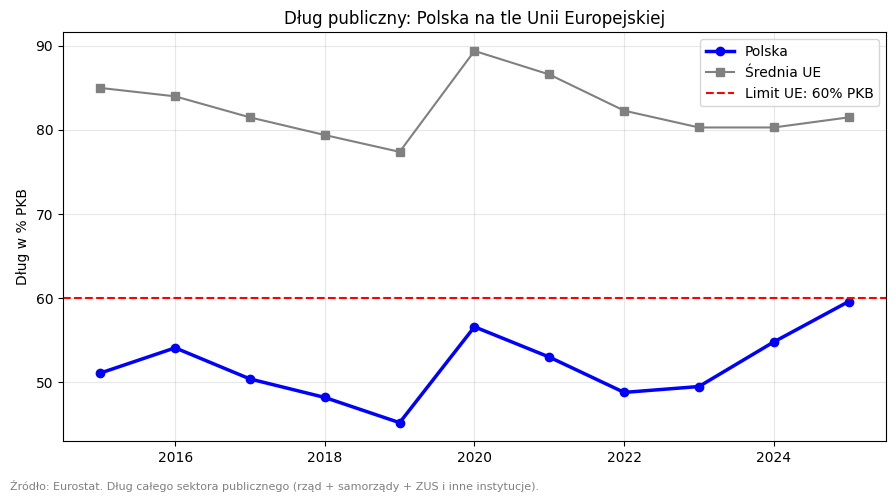

In [13]:
okres = dlug.loc[2015:]

plt.figure(figsize=(9, 5))
plt.plot(okres.index, okres["PL"], marker="o", label="Polska", linewidth=2.5, color="blue")
plt.plot(okres.index, okres["EU27_2020"], marker="s", label="Średnia UE", color="gray")
plt.axhline(60, color="red", linestyle="--", label="Limit UE: 60% PKB")

plt.ylabel("Dług w % PKB")
plt.title("Dług publiczny: Polska na tle Unii Europejskiej")
plt.figtext(0.01, 0.01, "Źródło: Eurostat. Dług całego sektora publicznego (rząd + samorządy + ZUS i inne instytucje).",
            fontsize=8, color="gray")
plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("img/dlug_na_przestrzeni_lat_pl_vs_ue.png", bbox_inches="tight")
plt.show()

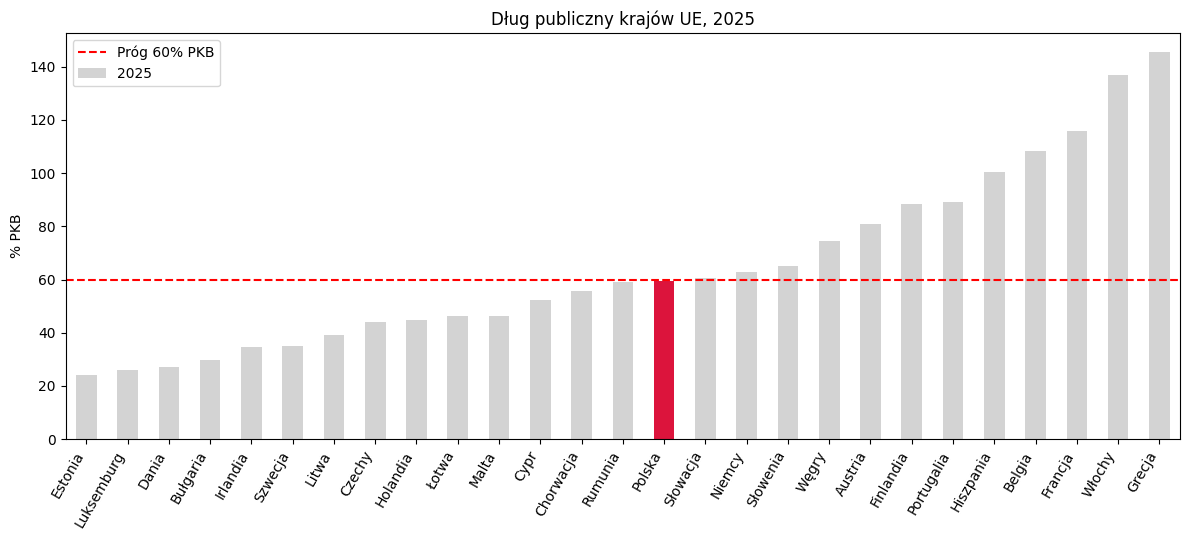

In [14]:
NAZWY = {
    "AT": "Austria", "BE": "Belgia", "BG": "Bułgaria", "HR": "Chorwacja",
    "CY": "Cypr", "CZ": "Czechy", "DK": "Dania", "EE": "Estonia",
    "FI": "Finlandia", "FR": "Francja", "EL": "Grecja", "ES": "Hiszpania",
    "NL": "Holandia", "IE": "Irlandia", "LT": "Litwa", "LU": "Luksemburg",
    "LV": "Łotwa", "MT": "Malta", "DE": "Niemcy", "PL": "Polska",
    "PT": "Portugalia", "RO": "Rumunia", "SK": "Słowacja", "SI": "Słowenia",
    "SE": "Szwecja", "HU": "Węgry", "IT": "Włochy",
}

rok = 2025
kraje_ue = [k for k in NAZWY if k in dlug.columns]   # tylko 27 krajów UE
r = dlug.loc[rok, kraje_ue].dropna().sort_values()

kolory = ["crimson" if k == "PL" else "lightgray" for k in r.index]
r.index = [NAZWY[k] for k in r.index]                # kody -> pełne nazwy

ax = r.plot(kind="bar", color=kolory, figsize=(12, 5.5))
ax.axhline(60, color="red", linestyle="--", label="Próg 60% PKB")
ax.set_ylabel("% PKB")
ax.set_title(f"Dług publiczny krajów UE, {rok}")
ax.legend()
plt.xticks(rotation=60, ha="right")                  # pełne nazwy są dłuższe, więc obracamy
plt.tight_layout()
plt.savefig("img/dlug_polska_vs_ue_2025.png", bbox_inches="tight")
plt.show()